# 00 · Data and baseline

**Goal of the project:** read one English answer and say who wrote it: a **human** (label 0) or **ChatGPT** (label 1).

This notebook is shared by the whole team. It does four things:

1. Loads the HC3 dataset and looks at it.
2. Finds and removes formatting "shortcuts" that would let a model cheat.
3. Splits the data into train, validation and test, and explores the training set.
4. Trains the simple baseline: TF-IDF + Logistic Regression.

Run it once, from top to bottom. The six model notebooks read the CSV files it writes.

In [1]:
import json
import re
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline

SEED = 42                      # same random seed in every notebook
DATA = Path('../data')         # the notebooks run from the notebooks/ folder
MODELS = Path('../models')
DOCS = Path('../docs')

## 1. Load the dataset

**HC3** (Human ChatGPT Comparison Corpus) has real questions. Each question has answers written by humans and answers written by ChatGPT. We use the English **Open QA** part.

The file `data/open_qa.jsonl` is a copy of the official file (revision `fdca6c0`), so everybody gets exactly the same data, even without internet.

In [2]:
raw = pd.read_json(DATA / 'open_qa.jsonl', lines=True)
print('Number of questions:', len(raw))
print('Columns:', list(raw.columns))

Number of questions: 1187
Columns: ['question', 'human_answers', 'chatgpt_answers']


In [3]:
# Look at one question and its two kinds of answers.
print('QUESTION:', raw.question[0])
print()
print('HUMAN ANSWER:', raw.human_answers[0][0])
print()
print('CHATGPT ANSWER:', raw.chatgpt_answers[0][0])

QUESTION: what composer used sound mass

HUMAN ANSWER: Composers and works include Barbara Kolb , Pauline Oliveros ' Sound Patterns for chorus (1961), Norma Beecroft 's From Dreams of Brass for chorus (1963–1964), and Nancy Van de Vate .A very early example is the opening of Jean-Féry Rebel 's ballet Les Elémens (1737–38), where chaos is represented by a gradually cumulating orchestral cluster of all seven notes of the D minor scale (Henck 2004, pp. 52–54).A later example is the third movement of Ruth Crawford Seeger 's String Quartet 1931 (Nonesuch H-71280) while more recently Phill Niblock 's multiple drone based music serves as an example.The use of "chords approaching timbres" begins with Debussy and Edgard Varèse often carefully scored individual instrumental parts so that they would fuse into one ensemble timbre or sound mass (Erickson 1975, pp. 18 and 21).Other examples include European "textural" compositions of the fifties and sixties such as Krzysztof Penderecki 's Threnody t

## 2. Look for shortcuts before cleaning

A **shortcut** is an easy signal that matches the label in *this* dataset by accident.
If we leave it, the model can get a high score without learning how humans and ChatGPT write.

We check three things in the first human answer and the first ChatGPT answer of every question:

| Check | Why it is a problem |
|---|---|
| The two characters `\n` | HC3 stores line breaks as a backslash and an `n`. If only ChatGPT answers have them, "`\n` → AI" is a free answer. |
| A space before `.` or `,` | Human answers come from Wikipedia with spacing like `Michigan .` If only humans have it, "space before a dot → human" is a free answer. |
| No space after a dot | Wikipedia sentences were glued together: `movement.Her Declaration`. If only humans have it, it is another free answer. |
| Empty brackets `()` | Wikipedia removed pronunciations and left `Dim sum () refers` or `(; born 1953)`. ChatGPT never writes empty brackets. |
| Website messages | Some "ChatGPT answers" are error messages like `network error`. They are not answers at all. |

In [4]:
WEBSITE_MESSAGES = ['network error', 'too many requests', 'content policy']

def count_problems(texts):
    backslash_n = 0
    space_before_dot = 0
    no_space_after_dot = 0
    empty_brackets = 0
    website_message = 0
    for text in texts:
        if '\\n' in text:
            backslash_n = backslash_n + 1
        if re.search(r' [.,;:]', text):
            space_before_dot = space_before_dot + 1
        if re.search(r'[a-z0-9)\]][.!?][A-Z]', text):
            no_space_after_dot = no_space_after_dot + 1
        if re.search(r'\(\s*[,;)]', text):
            empty_brackets = empty_brackets + 1
        for message in WEBSITE_MESSAGES:
            if message in text.lower():
                website_message = website_message + 1
    return [backslash_n, space_before_dot, no_space_after_dot, empty_brackets, website_message]

first_human = []
first_ai = []
for i in range(len(raw)):
    if len(raw.human_answers[i]) > 0 and len(raw.chatgpt_answers[i]) > 0:
        first_human.append(raw.human_answers[i][0])
        first_ai.append(raw.chatgpt_answers[i][0])

before = pd.DataFrame({'human answers': count_problems(first_human), 'ChatGPT answers': count_problems(first_ai)},
                      index=['contains \\n', 'space before . , ; :', 'no space after a dot', 'empty brackets "()" or "(;"', 'website message'])
print('Answers checked per class:', len(first_human))
before

Answers checked per class: 1187


,human answers,ChatGPT answers
contains \n,0,439
"space before . , ; :",726,4
no space after a dot,97,2
"empty brackets ""()"" or ""(;""",56,0
website message,0,5


**What the table shows:** `\n` appears only in ChatGPT answers. A space before punctuation, a missing space after a dot and empty brackets appear almost only in human answers.
All of them are formatting accidents, not writing style. We remove them in the next step.

## 3. Clean the answers

The `clean` function fixes one answer:

1. `\n` → a normal space.
2. Remove the `2 / 2` page counter that the ChatGPT website sometimes added at the start.
3. `(; born 1953)` → `(born 1953)`, `Dim sum () refers` → `Dim sum refers`, `Michigan .` → `Michigan.`, `( Bulgaria` → `(Bulgaria`, `Rebel 's` → `Rebel's`.
4. `movement.Her` → `movement. Her` (add the missing space after a dot).
5. Join repeated spaces into one.

**Stopwords:** we keep them on purpose. Small words like *the*, *however*, *I* and *it* are part of a writer's style, and style is exactly what we want the model to learn.
We also keep capital letters and punctuation for the same reason.

The `is_usable` function rejects empty answers and website messages.

In [5]:
def clean(text):
    if not isinstance(text, str):
        return ''
    text = text.replace('\\n', ' ')                  # 1. "\n" -> space
    text = re.sub(r'^\s*\d+ / \d+\s+', '', text)      # 2. remove "2 / 2" at the start
    text = re.sub(r'\(\s*[;,\s]*', '(', text)        # 3. "(; born" or "( , born" -> "(born"
    text = re.sub(r'\s*\(\)', '', text)                # 3. "Dim sum () refers" -> "Dim sum refers"
    text = re.sub(r'\s+([.,;:!?)])', r'\1', text)     # 3. "Michigan ." -> "Michigan."
    text = re.sub(r'\(\s+', '(', text)                # 3. "( Bulgaria" -> "(Bulgaria"
    text = re.sub(r" '(s\b)", r"'\1", text)           # 3. "Rebel 's" -> "Rebel's"
    text = re.sub(r"s ' ", "s' ", text)                # 3. "Oliveros ' Sound" -> "Oliveros' Sound"
    text = re.sub(r'([a-z0-9)\]][.!?])([A-Z])', r'\1 \2', text)   # 4. "movement.Her" -> "movement. Her"
    text = ' '.join(text.split())                     # 5. one space between words
    return text


def is_usable(text):
    if text == '':
        return False
    for message in WEBSITE_MESSAGES:
        if message in text.lower():
            return False
    return True


def first_good_answer(answers):
    # Take the first answer that is usable after cleaning.
    for answer in answers:
        cleaned = clean(answer)
        if is_usable(cleaned):
            return cleaned
    return ''


print(clean('It is the second largest city in Oakland County , Michigan .'))
print(clean('diabetes.\\n\\nSulfas work by stopping bacteria.'))
print(clean("the women's rights movement.Her Declaration"))
print(clean('Dim sum () refers to a style of Cantonese food'))

It is the second largest city in Oakland County, Michigan.
diabetes. Sulfas work by stopping bacteria.
the women's rights movement. Her Declaration
Dim sum refers to a style of Cantonese food


## 4. Build question pairs

For every question we keep **one human answer and one ChatGPT answer**. We call this a *pair*.

We skip a question when:
- it has no usable human answer or no usable ChatGPT answer,
- the question was already seen (duplicate question),
- one of the answers was already used by another question (duplicate answer).

In [6]:
pairs = []
seen_questions = set()
seen_answers = set()

for i in range(len(raw)):
    question = clean(raw.question[i]).lower()
    human = first_good_answer(raw.human_answers[i])
    ai = first_good_answer(raw.chatgpt_answers[i])

    if question == '' or human == '' or ai == '':
        continue
    if question in seen_questions:
        continue
    if human.lower() == ai.lower():
        continue
    if human.lower() in seen_answers or ai.lower() in seen_answers:
        continue

    pairs.append({'question': question, 'human': human, 'ai': ai})
    seen_questions.add(question)
    seen_answers.add(human.lower())
    seen_answers.add(ai.lower())

pairs = pd.DataFrame(pairs)
print('Usable pairs:', len(pairs))

Usable pairs: 1170


## 5. Split into train, validation and test

We randomly pick **500 pairs** (seed 42) so training is fast on a laptop or on Google Colab.

Then we split **by question**, not by answer: both answers of a question go to the same split.
If the human answer of a question were in train and the ChatGPT answer in test, the model could recognise the topic instead of the writer.

| Split | Pairs | Answers | Used for |
|---|---|---|---|
| train | 350 (70%) | 700 | learning the weights |
| validation | 75 (15%) | 150 | choosing settings (epoch, C) |
| test | 75 (15%) | 150 | the final score only, once |

In [7]:
pairs = pairs.sample(n=500, random_state=SEED).reset_index(drop=True)

train_pairs = pairs[0:350]
val_pairs = pairs[350:425]
test_pairs = pairs[425:500]


def pairs_to_rows(pair_table):
    rows = []
    for pair_id in pair_table.index:
        rows.append({'pair_id': pair_id, 'text': pair_table.human[pair_id], 'label': 0})
        rows.append({'pair_id': pair_id, 'text': pair_table.ai[pair_id], 'label': 1})
    table = pd.DataFrame(rows)
    table = table.sample(frac=1, random_state=SEED)   # shuffle the rows
    return table


train = pairs_to_rows(train_pairs)
val = pairs_to_rows(val_pairs)
test = pairs_to_rows(test_pairs)

train.to_csv(DATA / 'train.csv', index=False)
val.to_csv(DATA / 'val.csv', index=False)
test.to_csv(DATA / 'test.csv', index=False)

print('train:', len(train), 'answers')
print('val:  ', len(val), 'answers')
print('test: ', len(test), 'answers')

train: 700 answers
val:   150 answers
test:  150 answers


In [8]:
# Safety check: no question may appear in two splits.
train_ids = set(train.pair_id)
val_ids = set(val.pair_id)
test_ids = set(test.pair_id)
print('Questions shared by train and val: ', len(train_ids & val_ids))
print('Questions shared by train and test:', len(train_ids & test_ids))
print('Questions shared by val and test:  ', len(val_ids & test_ids))

Questions shared by train and val:  0
Questions shared by train and test: 0
Questions shared by val and test:   0


## 6. Check that the shortcuts are gone

Same check as before, now on the final CSV files. Every number must be **0**.

In [9]:
rows = []
for split_name, table in [('train', train), ('val', val), ('test', test)]:
    human_texts = table[table.label == 0].text
    ai_texts = table[table.label == 1].text
    human_counts = count_problems(human_texts)
    ai_counts = count_problems(ai_texts)
    rows.append({'split': split_name,
                 'human: \\n': human_counts[0], 'AI: \\n': ai_counts[0],
                 'human: space before dot': human_counts[1], 'AI: space before dot': ai_counts[1],
                 'human: no space after dot': human_counts[2], 'AI: no space after dot': ai_counts[2],
                 'human: empty brackets': human_counts[3], 'AI: empty brackets': ai_counts[3],
                 'human: website msg': human_counts[4], 'AI: website msg': ai_counts[4]})
pd.DataFrame(rows)

,split,human: \n,AI: \n,human: space before dot,AI: space before dot,human: no space after dot,AI: no space after dot,human: empty brackets,AI: empty brackets,human: website msg,AI: website msg
0,train,0,0,0,0,0,0,0,0,0,0
1,val,0,0,0,0,0,0,0,0,0,0
2,test,0,0,0,0,0,0,0,0,0,0


## 7. Explore the training set

We look at three things: how many answers each class has, how long the answers are, and one example of each.

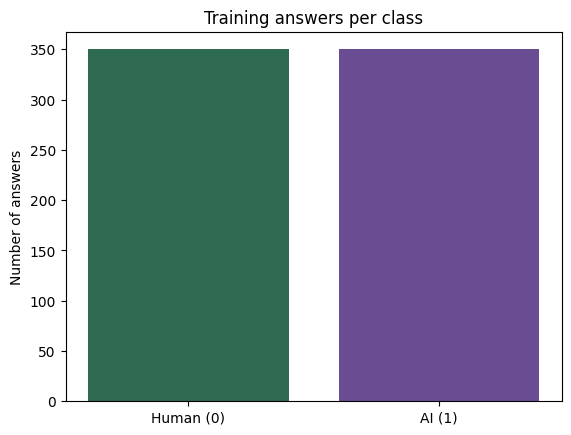

label
0    350
1    350
Name: count, dtype: int64


In [10]:
counts = train.label.value_counts().sort_index()
plt.bar(['Human (0)', 'AI (1)'], counts.values, color=['#2d6a4f', '#6a4c93'])
plt.title('Training answers per class')
plt.ylabel('Number of answers')
plt.savefig(DOCS / 'class-balance.png', bbox_inches='tight')
plt.show()
print(counts)

             mean    50%  min    max
label                               
0       29.131429   24.0  2.0  151.0
1      116.931429  103.0  7.0  331.0


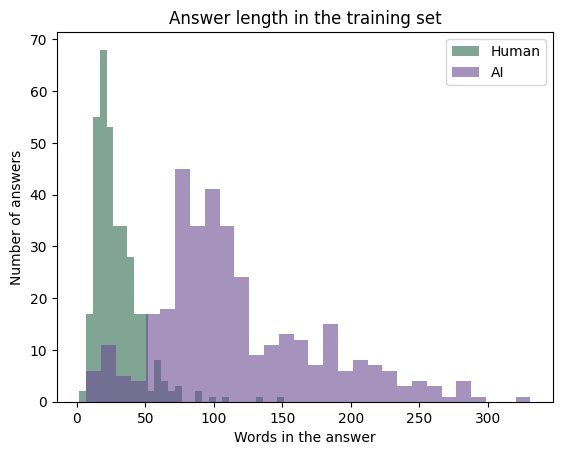

In [11]:
train['words'] = train.text.str.split().str.len()
print(train.groupby('label').words.describe()[['mean', '50%', 'min', 'max']])

plt.hist(train[train.label == 0].words, bins=30, alpha=0.6, label='Human', color='#2d6a4f')
plt.hist(train[train.label == 1].words, bins=30, alpha=0.6, label='AI', color='#6a4c93')
plt.xlabel('Words in the answer')
plt.ylabel('Number of answers')
plt.title('Answer length in the training set')
plt.legend()
plt.savefig(DOCS / 'answer-length.png', bbox_inches='tight')
plt.show()

**What we see:** the classes are balanced (350 each). ChatGPT answers are usually much longer than human answers.
Length is a real style difference, not a formatting accident, so we keep it. But it means a model might lean on length: a short ChatGPT answer or a long human answer is a likely mistake. We look for this in the error analysis.

In [12]:
print('HUMAN EXAMPLE:')
print(train[train.label == 0].text.iloc[0])
print()
print('AI EXAMPLE:')
print(train[train.label == 1].text.iloc[0])

HUMAN EXAMPLE:
Elizabeth Cady Stanton (November 12, 1815 – October 26, 1902) was an American social activist, abolitionist, and leading figure of the early women's rights movement. Her Declaration of Sentiments, presented at the first women's rights convention held in 1848 in Seneca Falls, New York, is often credited with initiating the first organized women's rights and women's suffrage movements in the United States.

AI EXAMPLE:
A law enforcement murder book is a comprehensive document that is used to collect and organize all of the information about a murder investigation. It typically includes details about the victim, suspects, witnesses, forensic evidence, and any other relevant information. The murder book is used by law enforcement agencies to track the progress of the investigation, coordinate efforts among different departments and agencies, and ensure that all aspects of the case are thoroughly documented. It is an important tool for helping investigators solve the case and

## 8. Baseline: TF-IDF + Logistic Regression

The baseline is the simple model that every transformer must beat.

- **TF-IDF** turns each answer into numbers: one number per word. A word gets a high number when it appears often in this answer but not in every answer.
- **Logistic Regression** learns one weight per word and adds them up to get the probability of "AI".

`C` controls how strongly the model is allowed to fit the training data. We try three values and keep the one with the best **validation F1**. The test set is not used here.

In [13]:
best_f1 = -1
best_c = None

for c in [0.1, 1.0, 10.0]:
    model = make_pipeline(TfidfVectorizer(max_features=10000),
                          LogisticRegression(C=c, max_iter=1000, random_state=SEED))
    model.fit(train.text, train.label)
    val_predictions = model.predict(val.text)
    score = f1_score(val.label, val_predictions)
    print('C =', c, '-> validation F1 =', round(score, 4))
    if score > best_f1:
        best_f1 = score
        best_c = c
        baseline = model

print('Best C:', best_c)

C = 0.1 -> validation F1 = 0.8182
C = 1.0 -> validation F1 = 0.8333
C = 10.0 -> validation F1 = 0.8608
Best C: 10.0


In [14]:
# Save the best baseline so the API can load it later.
folder = MODELS / 'Baseline'
folder.mkdir(parents=True, exist_ok=True)
joblib.dump(baseline, folder / 'pipeline.joblib')

size_bytes = (folder / 'pipeline.joblib').stat().st_size
validation_result = {'f1': best_f1, 'size_bytes': size_bytes}
(DOCS / 'Baseline-validation.json').write_text(json.dumps(validation_result, indent=2))
print('Saved. Size:', round(size_bytes / 1_000_000, 2), 'MB')

Saved. Size: 0.35 MB


In [15]:
# Which words push an answer towards Human or towards AI?
words = baseline.named_steps['tfidfvectorizer'].get_feature_names_out()
weights = baseline.named_steps['logisticregression'].coef_[0]
word_weights = pd.Series(weights, index=words).sort_values()
print('Words that point to HUMAN:', list(word_weights.index[:15]))
print('Words that point to AI:   ', list(word_weights.index[-15:]))

Words that point to HUMAN: ['largest', 'city', 'definition', 'river', 'american', 'turkey', 'town', 'officially', 'submitted', 'ratification', 'southern', 'bottom', 'both', 'dredger', 'thirteen']
Words that point to AI:    ['that', 'in', 'he', 'can', 'has', 'including', 'you', 'located', 'it', 'are', 'was', 'is', 'to', 'the', 'and']


## 9. Final test of the baseline

Now we use the test set **once**. We measure:

- **accuracy**: how many answers were right,
- **precision**: of the answers we called AI, how many were really AI,
- **recall**: of the real AI answers, how many we found,
- **F1**: one number that balances precision and recall (our main metric),
- **size** of the saved model and **time** to classify one answer on the CPU.

In [16]:
test_predictions = baseline.predict(test.text)

accuracy = accuracy_score(test.label, test_predictions)
precision = precision_score(test.label, test_predictions)
recall = recall_score(test.label, test_predictions)
f1 = f1_score(test.label, test_predictions)

# Time: classify 50 answers one by one and take the average.
start = time.perf_counter()
for text in test.text[:50]:
    baseline.predict([text])
ms_per_text = (time.perf_counter() - start) / 50 * 1000

result = {'model': 'Baseline', 'accuracy': accuracy, 'precision': precision, 'recall': recall,
          'f1': f1, 'size_MB': size_bytes / 1_000_000, 'ms_per_text': ms_per_text}
(DOCS / 'Baseline.json').write_text(json.dumps(result, indent=2))
pd.DataFrame([result]).round(4)

,model,accuracy,precision,recall,f1,size_MB,ms_per_text
0,Baseline,0.86,0.7872,0.9867,0.8757,0.355,0.2419


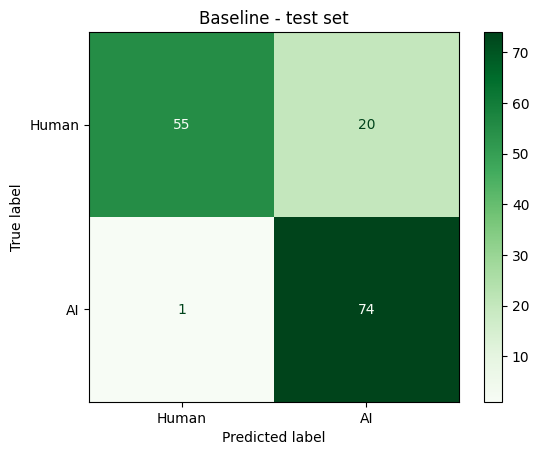

In [17]:
ConfusionMatrixDisplay.from_predictions(test.label, test_predictions, display_labels=['Human', 'AI'], cmap='Greens')
plt.title('Baseline - test set')
plt.savefig(DOCS / 'Baseline-matrix.png', bbox_inches='tight')
plt.show()

In [18]:
# Look at the mistakes.
test['predicted'] = test_predictions
mistakes = test[test.label != test.predicted]
print('Number of mistakes:', len(mistakes))
for i in range(min(4, len(mistakes))):
    row = mistakes.iloc[i]
    print()
    print('Actual:', 'AI' if row.label == 1 else 'Human', '| Predicted:', 'AI' if row.predicted == 1 else 'Human')
    print(row.text[:300])

Number of mistakes: 21

Actual: Human | Predicted: AI
Big Time Rush (BTR) is an American television series created by Scott Fellows about the Hollywood misadventures of four hockey players from Minnesota —Kendall, James, Carlos, and Logan, after they are selected to form a boy band.

Actual: Human | Predicted: AI
A will or testament is a legal declaration by which a person, the testator, names one or more persons to manage his/her estate and provides for the transfer of his property at death.

Actual: Human | Predicted: AI
Galveston County is a county located in the U.S. state of Texas within the Houston–Sugar Land–Baytown metropolitan area.

Actual: Human | Predicted: AI
It is a guarantee by the transferring financial institution that the signature is genuine and the financial institution accepts liability for any forgery. They also limit the liability of the transfer agent who accepts the certificates.


## Summary

- The raw HC3 file had five formatting accidents that belonged to one class only (`\n`, space before punctuation, no space after a dot, empty brackets, website messages). After cleaning, all of them are 0 in every split.
- Split: 700 / 150 / 150 answers, balanced, and no question is shared between splits.
- ChatGPT answers are about four times longer (median 103 vs 24 words). This is real style, so we keep it.
- Baseline: the best `C` on validation was 10 (F1 0.861). Test: **accuracy 0.860, F1 0.876**, 0.36 MB, 0.24 ms per answer.
- The baseline almost never misses an AI answer (recall 0.987), but it calls 20 human answers AI (precision 0.787). Function words (`the`, `and`, `is`) point to AI, and topic words (`city`, `river`, `largest`) point to human.